# Лабораторная работа 3. Измерение качества классификатора

**Задача.** Самостоятельно собрать простой фильтр электронных писем на правилах, проверить его на примерах и разобрать ошибки.

**Библиотеки машинного обучения не используются.**

In [1]:
student = "Липатникова Надежда Михайловна"   # Фамилия Имя Отчество
group = "251-952"     # номер группы
print(student, group)

Липатникова Надежда Михайловна 251-952


**Основные ссылки.** Полный перечень ресурсов приведен в конце ноутбука.

| Ресурс | Адрес |
|---|---|
| Mitchell T. Machine Learning. McGraw-Hill, 1997 (гл. 1) | https://www.cs.cmu.edu/~tom/mlbook.html |
| Документация Python: встроенные типы | https://docs.python.org/3/library/stdtypes.html |
| pandas: отображение таблиц | https://pandas.pydata.org/docs/ |

## 0. Устройство работы

**Цель.** Подготовить рабочую папку и понять порядок выполнения.

**Сюжет.** Представьте небольшой почтовый сервис: пользователи жалуются на спам, а вам поручили первый прототип фильтра. Готовой ML-модели нет. Можно посмотреть на письма, выбрать признаки, придумать правила и проверить, насколько они работают.

**Чем это отличается от экспертной системы.** В работах про машину Тьюринга и ELIZA вы уже писали правила вида «если условие – сделать действие». Здесь снова правила, но задача другая: письмо нужно **классифицировать**, а качество решения – **измерить**.

После этой работы вы должны уверенно уметь:

1. описать объект признаками и собрать из них решающее правило (баллы + порог);
2. читать матрицу ошибок: TP, TN, FP, FN;
3. считать и объяснять Accuracy, Precision, Recall, F1;
4. видеть компромисс: низкий порог ловит больше спама, но растут ложные тревоги;
5. отделять настройку на наборе для разработки от проверки на новых письмах;
6. объяснить, чем ручной фильтр похож на будущую ML-модель и чем отличается (веса задает человек, а не данные).

В этой работе вы **не обучаете модель**. Вы вручную конструируете классификатор на правилах – чтобы пройти путь от письма до метрик и понять, что именно потом будет автоматизировать машинное обучение.

В ячейках, где нужно заполнить данные, рядом в комментарии дан `# Пример:`.

| Часть | Что реализуется |
|---|---|
| 1. Письма без меток | первое предположение о спаме и обычной почте |
| 2. Признаки | списки слов и фраз, функция извлечения признаков |
| 3. Фильтр | веса, сумма баллов, порог, предсказания на наборе для разработки |
| 4. Настройка | матрица ошибок, метрики, выбор окончательного порога |
| 5. Тест | независимая проверка на новых письмах |
| 6. Итог | сравнение выборок, разбор ошибок, выводы |

**Порядок.** Блоки сверху вниз. Метки тестовой выборки открывают только после фиксации порога и весов. Не подстраивайте правила, глядя на тестовые ответы.

**Положительный класс** – «спам». Это важно для TP, FP, TN и FN.

**0.1. Заполнить сведения о студенте (первая ячейка), подготовить папку данных и вспомогательные функции.**

In [2]:
import sys, os, hashlib
from pathlib import Path
from IPython.display import display

try:
    import pandas as pd
except ImportError:
    pd = None

cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
os.chdir(ROOT)
DATA = ROOT / "data"
DATA.mkdir(exist_ok=True)

if not student.strip() or not group.strip():
    print("Заполнить сведения о студенте в первой ячейке и выполнить ее заново")

AUTHOR = hashlib.sha256(f"{student.strip()}|{group.strip()}".encode("utf-8")).hexdigest()[:8]

CHECKS = []

def start_checks():
    CHECKS.clear()

def check(label, got, expected):
    ok = got == expected
    CHECKS.append(ok)
    print(("OK       " if ok else "ОШИБКА   ") + label)
    if not ok:
        print("   ожидалось:", repr(expected))
        print("   получено: ", repr(got))
    return ok

def finish_checks():
    print(f"\nПроверок пройдено: {sum(CHECKS)} из {len(CHECKS)}")

def show_table(rows):
    if pd is not None:
        display(pd.DataFrame(rows))
    else:
        for row in rows:
            print(row)

print("Python:", sys.version.split()[0])
print("Рабочая папка:", ROOT)
print("Папка данных:", DATA)
print("Код автора:", AUTHOR)

Python: 3.10.3
Рабочая папка: c:\Users\Nadezhda\work\lab3
Папка данных: c:\Users\Nadezhda\work\lab3\data
Код автора: fb92021c


## Часть 1. Письма без меток

**Цель.** Посмотреть на набор писем для разработки без эталонных меток и зафиксировать первое впечатление.

**Зачем это нужно.** Спамом считаем нежелательные рекламные или обманные сообщения. Обычными письмами – рабочую переписку, уведомления и рассылки. В реальной жизни граница не всегда однозначна, поэтому в учебном наборе метки уже заданы: по ним потом можно сравнить предсказания фильтра с эталоном.

Сначала смотрим на письма без правильных ответов – как на входящие в почтовом ящике.

**1.1. Выполнить ячейку с набором писем для разработки.**

Это набор для придумывания и настройки правил. Правильные метки откроются позже, в части 3.

In [3]:
development_emails = [
    {"id": "D01", "sender": "promo@bonus-center.example", "subject": "Вы выиграли приз – заберите сегодня", "body": "Поздравляем! Перейдите по ссылке и получите подарок: https://bonus.example/claim"},
    {"id": "D02", "sender": "lecturer@university.example", "subject": "Материалы к завтрашней лекции", "body": "Добрый день! Материалы и ссылка на аудиторию доступны здесь: https://university.example/course"},
    {"id": "D03", "sender": "security-check@account-help.example", "subject": "Подтвердите пароль", "body": "Чтобы сохранить доступ, войдите в аккаунт и укажите пароль: https://account-help.example/login"},
    {"id": "D04", "sender": "office@university.example", "subject": "Протокол совещания", "body": "Коллеги, направляю протокол вчерашнего совещания. Замечания можно прислать ответным письмом."},
    {"id": "D05", "sender": "sale@fast-offers.example", "subject": "Скидка 80% только сегодня", "body": "Покупайте со скидкой. Доставка бесплатно. Подробности: https://fast-offers.example"},
    {"id": "D06", "sender": "bank@samplebank.example", "subject": "Выписка за месяц готова", "body": "Ваша выписка доступна в приложении банка: https://samplebank.example/app"},
    {"id": "D07", "sender": "work@income-now.example", "subject": "Дополнительный доход из дома", "body": "Предлагаем удаленную подработку. Можно начать без опыта. Ответьте на письмо, чтобы узнать условия."},
    {"id": "D08", "sender": "courses@university.example", "subject": "Запись вебинара доступна", "body": "Спасибо за участие! Запись вебинара и дополнительные материалы: https://university.example/webinar"},
    {"id": "D09", "sender": "gift@surprise-mail.example", "subject": "Ваш приз уже готов", "body": "Ответьте на это сообщение, и мы расскажем, как получить приз."},
    {"id": "D10", "sender": "project@company.example", "subject": "Срочно проверьте таблицу проекта", "body": "Коллеги, обновил таблицу. Пожалуйста, посмотрите новую версию: https://company.example/project"},
    {"id": "D11", "sender": "notify@membership-check.example", "subject": "Подтвердите продление подписки", "body": "Для подтверждения перейдите по ссылке и введите код из SMS: https://membership-check.example/confirm"},
    {"id": "D12", "sender": "new-partner@partner.example", "subject": "Документы по совместному проекту", "body": "Отправляю документы и ссылку на общую папку: https://partner.example/shared"},
]

In [4]:
show_table([
    {"ID": e["id"], "Отправитель": e["sender"], "Тема": e["subject"], "Текст": e["body"]}
    for e in development_emails
])

,ID,Отправитель,Тема,Текст
0,D01,promo@bonus-center.example,Вы выиграли приз – заберите сегодня,Поздравляем! Перейдите по ссылке и получите по...
1,D02,lecturer@university.example,Материалы к завтрашней лекции,Добрый день! Материалы и ссылка на аудиторию д...
2,D03,security-check@account-help.example,Подтвердите пароль,"Чтобы сохранить доступ, войдите в аккаунт и ук..."
3,D04,office@university.example,Протокол совещания,"Коллеги, направляю протокол вчерашнего совещан..."
4,D05,sale@fast-offers.example,Скидка 80% только сегодня,Покупайте со скидкой. Доставка бесплатно. Подр...
5,D06,bank@samplebank.example,Выписка за месяц готова,Ваша выписка доступна в приложении банка: http...
6,D07,work@income-now.example,Дополнительный доход из дома,Предлагаем удаленную подработку. Можно начать ...
7,D08,courses@university.example,Запись вебинара доступна,Спасибо за участие! Запись вебинара и дополнит...
8,D09,gift@surprise-mail.example,Ваш приз уже готов,"Ответьте на это сообщение, и мы расскажем, как..."
9,D10,project@company.example,Срочно проверьте таблицу проекта,"Коллеги, обновил таблицу. Пожалуйста, посмотри..."


**1.2. Выбрать три подозрительных и два обычных письма.**

До написания правил зафиксируйте первое впечатление: три письма кажутся подозрительными, два – обычными. Пока не пытайтесь угадать эталонные метки.

In [5]:
# Пример: ["D01", "D03", "D05"]
my_suspicious_first = ["D05", "D07", "D09"]

# Пример: ["D02", "D04"]
my_normal_first = ["D04", "D12"]

In [6]:
print("Подозрительными выбраны:", my_suspicious_first)
print("Обычными выбраны:", my_normal_first)

Подозрительными выбраны: ['D05', 'D07', 'D09']
Обычными выбраны: ['D04', 'D12']


На выбор подозрительных писем повлияло навязывание какого-то действия и базовые рекламные структуры.

На выбор обычных писем повлиял контекст письма, который явно показывает, что это важная информация по работе.

## Часть 2. Признаки письма

**Цель.** Задать списки признаков и реализовать функцию извлечения признаков.

**Зачем это нужно.** Фильтр не «понимает» письмо как человек. Мы заранее выделяем несколько свойств (**признаков**), которые используем при решении.

В работе четыре признака:

1. подозрительные слова и выражения;
2. наличие ссылки;
3. неизвестный отправитель;
4. запрос чувствительных данных.

Список не универсальный: ссылка сама по себе не равна спаму. Одного признака обычно недостаточно.

**2.1. Выполнить ячейку со списком доверенных отправителей.**

Ниже – небольшой список адресов, которым условный пользователь доверяет. В реальном сервисе его могли бы собирать из контактов и истории переписки.

In [7]:
TRUSTED_SENDERS = {
    "lecturer@university.example",
    "office@university.example",
    "bank@samplebank.example",
    "courses@university.example",
    "project@company.example",
    "events@university.example",
    "news@knownshop.example",
}

In [8]:
print("Доверенные адреса:")
for address in sorted(TRUSTED_SENDERS):
    print("-", address)

Доверенные адреса:
- bank@samplebank.example
- courses@university.example
- events@university.example
- lecturer@university.example
- news@knownshop.example
- office@university.example
- project@company.example


**2.2. Составить список подозрительных слов и выражений (7-10).**

Обычное письмо тоже может содержать «срочно» или «скидка». Выбирайте выражения, которые для вашей логики действительно сигналят о нежелательном сообщении.

In [9]:
# Пример: ["выиграли", "приз"]
SUSPICIOUS_WORDS = [
    "только сегодня",
    "приз",
    "введите пароль",
    "подарок",
    "ответьте на письмо, чтобы узнать",
]

In [10]:
print(SUSPICIOUS_WORDS)

['только сегодня', 'приз', 'введите пароль', 'подарок', 'ответьте на письмо, чтобы узнать']


**2.3. Составить список фраз о запросе личных данных (не менее пяти).**

Это более сильный сигнал, чем просто ссылка: просьба ввести пароль, код из SMS или данные карты на неизвестном сайте должна вызывать особое подозрение.

In [13]:
# Пример: ["пароль", "код из sms", "данные карты", "войдите в аккаунт"]
SENSITIVE_PHRASES = [
    "пароль",
    "аккаунт",
    "данные карты",
    "сохранить доступ",
    "подтвердите",
]

In [14]:
print(SENSITIVE_PHRASES)

['пароль', 'аккаунт', 'данные карты', 'сохранить доступ', 'подтвердите']


**2.4. Реализовать функцию `extract_features(email)`.**

Функция получает одно письмо и возвращает словарь признаков. Для простоты достаточно искать подстроки в тексте: способ ограниченный и может ошибаться, но для нашей учебной задачи подойдет. А в чем кстати говоря ограничение? Почему может ошибаться?

1) Вход: письмо-словарь с полями `sender`, `subject`, `body`.
2) Выход: словарь признаков.
3) Ключи: `suspicious_hits`, `suspicious_count`, `has_link`, `sender_is_known`, `unknown_sender`, `asks_sensitive`.
4) `suspicious_hits` – список найденных подозрительных слов из `SUSPICIOUS_WORDS` (без учета регистра).
5) `suspicious_count` – длина этого списка.
6) `has_link` – есть ли в теме или тексте `http://`, `https://` или `www.`.
7) `sender_is_known` – входит ли отправитель в `TRUSTED_SENDERS`.
8) `unknown_sender` – обратное к `sender_is_known`.
9) `asks_sensitive` – есть ли в теме или тексте любая фраза из `SENSITIVE_PHRASES`.

In [15]:
def extract_features(email):

    sender = email.get("sender", "") or ""
    subject = email.get("subject", "") or ""
    body = email.get("body", "") or ""

    # Объединяем тему и тело; sender для поиска слов не используем,
    # чтобы адрес не давал ложных совпадений (например, "bank" в домене).
    text = f"{subject}\n{body}".lower()

    # 1. Подозрительные слова
    suspicious_hits = [w for w in SUSPICIOUS_WORDS if w in text]

    # 2. Ссылка в теме или тексте
    has_link = any(marker in text for marker in ("http://", "https://", "www."))

    # 3. Доверенный отправитель
    sender_is_known = sender.lower() in TRUSTED_SENDERS

    # 4. Запрос чувствительных данных
    asks_sensitive = any(p in text for p in SENSITIVE_PHRASES)

    return {
        "suspicious_hits": suspicious_hits,
        "suspicious_count": len(suspicious_hits),
        "has_link": has_link,
        "sender_is_known": sender_is_known,
        "unknown_sender": not sender_is_known,
        "asks_sensitive": asks_sensitive,
    }

In [16]:
extract_features(development_emails[0])

{'suspicious_hits': ['приз', 'подарок'],
 'suspicious_count': 2,
 'has_link': True,
 'sender_is_known': False,
 'unknown_sender': True,
 'asks_sensitive': False}

**2.5. Вывести признаки всех писем набора для разработки.**

Если результаты выглядят странно (например, у всех писем нет ссылок), вернитесь к спискам и к функции `extract_features`.

In [17]:
development_features = []
for email in development_emails:
    features = extract_features(email)
    development_features.append({
        "ID": email["id"],
        "Подозрительные слова": ", ".join(features["suspicious_hits"]) or "–",
        "Количество слов": features["suspicious_count"],
        "Есть ссылка": features["has_link"],
        "Отправитель знаком": features["sender_is_known"],
        "Просит личные данные": features["asks_sensitive"],
    })

show_table(development_features)

,ID,Подозрительные слова,Количество слов,Есть ссылка,Отправитель знаком,Просит личные данные
0,D01,"приз, подарок",2,True,False,False
1,D02,–,0,True,True,False
2,D03,–,0,True,False,True
3,D04,–,0,False,True,False
4,D05,только сегодня,1,True,False,False
5,D06,–,0,True,True,False
6,D07,"ответьте на письмо, чтобы узнать",1,False,False,False
7,D08,–,0,True,True,False
8,D09,приз,1,False,False,False
9,D10,–,0,True,True,False


**Пояснение к части 2.** Своими словами записать (3-4 предл.): какой признак надежнее и какой чаще вводит в заблуждение.

Из полученной таблицы видно, что самый надёжный признак — это asks_sensitive (запрос личных данных): он срабатывает ровно на двух письмах (D03 и D11), и оба действительно фишинговые. Просьба ввести пароль или код из SMS почти не встречается в легитимной переписке, поэтому даёт мало ложных срабатываний. Признак sender_is_known тоже полезен, но требует аккуратности: D12 от new-partner@partner.example формально «незнаком», хотя письмо легитимное, — то есть один только неизвестный отправитель ещё не приговор.

Чаще всего вводит в заблуждение признак has_link: ссылка есть в 8 из 12 писем, включая совершенно нормальные (D02, D06, D08, D10), поэтому сама по себе она почти ничего не различает и годится лишь как усилитель в сочетании с другими сигналами. Список подозрительных слов тоже ненадёжен: он ловит D01, D05, D07, D09, но пропускает фишинговые D03 и D11, где опасность в запросе данных, а не в «призе» или «скидке»; к тому же слова вроде «подарок» или «только сегодня» могут встретиться и в легитимной рассылке.

## Часть 3. Логика фильтра

**Цель.** Назначить веса, посчитать сумму баллов и отнести письмо к спаму или обычной почте по порогу.

**Зачем это нужно.** Признаки превращаются в систему баллов: чем выше сумма, тем скорее фильтр отправит письмо в спам. Просьба ввести пароль – сильный сигнал; одна ссылка – слабый, потому что ссылки бывают и в обычной переписке.

Веса и порог задаете вы и это не обучение модели, так как алгоритм в нашем случае сам ничего не подбирает.

**3.1. Назначить веса всем четырем признакам.**

Не ставьте всем признакам одинаковую важность автоматически. Подумайте, какие сигналы сильнее свидетельствуют о нежелательном письме:

- подозрительные слова – баллы за каждое найденное выражение;
- ссылка – дополнительные баллы;
- неизвестный отправитель – дополнительные баллы;
- запрос чувствительных данных – сильный сигнал.

In [18]:
# Пример: {"suspicious_term": 1}
WEIGHTS = {
    "suspicious_term": 1,
    "has_link": 1,
    "unknown_sender": 2,
    "asks_sensitive": 4,
}

In [19]:
print(WEIGHTS)

{'suspicious_term': 1, 'has_link': 1, 'unknown_sender': 2, 'asks_sensitive': 4}


**3.2. Реализовать функцию `score_email(email)`.**

Фильтр должен решать только по самому письму и выбранным признакам, без эталонной метки.

1) Вход: письмо-словарь.
2) Выход: число – сумма баллов.
3) Функция вызывает `extract_features`.
4) За каждый элемент из `suspicious_hits` добавляется вес `WEIGHTS["suspicious_term"]` (то есть `suspicious_count * вес`).
5) Если `has_link` – добавить `WEIGHTS["has_link"]`.
6) Если `unknown_sender` – добавить `WEIGHTS["unknown_sender"]`.
7) Если `asks_sensitive` – добавить `WEIGHTS["asks_sensitive"]`.

In [20]:
def score_email(email):

    features = extract_features(email)

    score = 0

    # 1. Подозрительные слова: вес за каждое найденное выражение
    score += features["suspicious_count"] * WEIGHTS["suspicious_term"]

    # 2. Ссылка в письме
    if features["has_link"]:
        score += WEIGHTS["has_link"]

    # 3. Незнакомый отправитель
    if features["unknown_sender"]:
        score += WEIGHTS["unknown_sender"]

    # 4. Запрос чувствительных данных
    if features["asks_sensitive"]:
        score += WEIGHTS["asks_sensitive"]

    return score

In [21]:
score_email(development_emails[0])

5

**3.3. Выбрать первоначальный порог и реализовать `classify_email`.**

Порог – сумма баллов, начиная с которой письмо считается спамом. Например, при пороге 3: 0–2 балла → обычное письмо, 3 и больше → спам. Позже порог можно менять и смотреть, как меняется поведение фильтра.

1) Задать порог `THRESHOLD` (целое число).
2) Функция `classify_email(email, threshold=THRESHOLD)` вызывает `score_email`.
3) Если баллы не ниже порога – вернуть `"спам"`, иначе `"не спам"`.

In [22]:
THRESHOLD = 4

In [23]:
def classify_email(email, threshold=THRESHOLD):
    score = score_email(email)
    if score >= threshold:
        return "спам"
    return "не спам"

print("Первоначальный порог:", THRESHOLD)
print("Пример предсказания:", classify_email(development_emails[0]))

Первоначальный порог: 4
Пример предсказания: спам


**3.4. Запустить фильтр на наборе для разработки.**

Сначала смотрим баллы и решения фильтра. Качество пока не оцениваем: проверяем, что правила вообще работают.

In [24]:
development_predictions = []
for email in development_emails:
    development_predictions.append({
        "ID": email["id"],
        "Баллы": score_email(email),
        "Предсказание фильтра": classify_email(email),
    })

show_table(development_predictions)

,ID,Баллы,Предсказание фильтра
0,D01,5,спам
1,D02,1,не спам
2,D03,7,спам
3,D04,0,не спам
4,D05,4,спам
5,D06,1,не спам
6,D07,3,не спам
7,D08,1,не спам
8,D09,3,не спам
9,D10,1,не спам


**3.5. Открыть эталонные метки набора для разработки и сравнить с предсказаниями.**

Это набор для разработки и настройки правил. Он **не является тестовым набором**.

In [25]:
DEVELOPMENT_LABELS = {
    "D01": 1, "D02": 0, "D03": 1, "D04": 0,
    "D05": 1, "D06": 0, "D07": 1, "D08": 0,
    "D09": 1, "D10": 0, "D11": 1, "D12": 0,
}

def prediction_to_int(prediction):
    return 1 if prediction == "спам" else 0

comparison_dev = []
for email in development_emails:
    pred = prediction_to_int(classify_email(email))
    true = DEVELOPMENT_LABELS[email["id"]]
    comparison_dev.append({
        "ID": email["id"],
        "Правильная метка": "спам" if true == 1 else "не спам",
        "Предсказание": "спам" if pred == 1 else "не спам",
        "Результат": "верно" if pred == true else "ОШИБКА",
    })

show_table(comparison_dev)

,ID,Правильная метка,Предсказание,Результат
0,D01,спам,спам,верно
1,D02,не спам,не спам,верно
2,D03,спам,спам,верно
3,D04,не спам,не спам,верно
4,D05,спам,спам,верно
5,D06,не спам,не спам,верно
6,D07,спам,не спам,ОШИБКА
7,D08,не спам,не спам,верно
8,D09,спам,не спам,ОШИБКА
9,D10,не спам,не спам,верно


**Пояснение к части 3.** Своими словами записать (3-4 предл.): какие письма классифицированы неправильно и почему.

Неправильно классифицированы два письма — D07 («Дополнительный доход из дома») и D09 («Ваш приз уже готов»): оба набрали по 3 балла и при пороге 4 попали в «не спам». Причина в том, что у них сработало только по одному подозрительному выражению («доход из дома» и «приз» соответственно) плюс штраф за незнакомого отправителя, а ссылки и запроса личных данных нет — то есть не хватило «усилителей», которые обычно добивают балл до порога. По сути, это письма из «серой зоны»: они действительно сомнительные (приманка выгодой), но эвристика по отдельным словам не отличает их от легитимного письма нового партнёра D12, который набирает те же 3 балла. Снижение порога до 3 поймало бы D07 и D09, но тогда в спам ошибочно уйдёт D12 — это и есть компромисс между полнотой и точностью, который придётся учитывать при настройке фильтра.



## Часть 4. Настройка порога и метрики

**Цель.** Посчитать TP, TN, FP, FN, вычислить метрики и выбрать окончательный порог.

**Зачем это нужно.** Порог задает, насколько легко фильтр отправляет письмо в спам.

- Низкий порог: фильтр находит больше спама, но чаще ошибочно отправляет обычную почту в спам.
- Высокий порог: фильтр осторожнее и реже тревожит пользователя, но часть спама может пропустить.

Настраивать порог можно только на наборе для разработки. Тестовые письма пока не открываем.

**4.1. Вручную заполнить TP, TN, FP и FN на наборе для разработки.**

Положительный класс – спам. Сначала по таблице сравнения попробуйте определить значения вручную, затем следующая ячейка проверит подсчет.

- **TP:** спам правильно обнаружен.
- **TN:** обычное письмо правильно оставлено во входящих.
- **FP:** обычное письмо ошибочно отправлено в спам (ложная тревога).
- **FN:** спам пропущен фильтром.

In [26]:
# Пример: {"TP": 4}
manual_dev_counts = {
    "TP": 4,
    "TN": 6,
    "FP": 0,
    "FN": 2,
}

In [27]:
print(manual_dev_counts)

{'TP': 4, 'TN': 6, 'FP': 0, 'FN': 2}


**4.2. Выполнить ячейку с функцией `get_confusion_counts` и проверить ручной подсчет.**

Автоматический подсчет нужен, чтобы сверить вашу ручную разметку ошибок.

In [28]:
def get_confusion_counts(emails, labels, threshold):
    counts = {"TP": 0, "TN": 0, "FP": 0, "FN": 0}
    for email in emails:
        true_label = labels[email["id"]]
        predicted_label = prediction_to_int(classify_email(email, threshold))
        if true_label == 1 and predicted_label == 1:
            counts["TP"] += 1
        elif true_label == 0 and predicted_label == 0:
            counts["TN"] += 1
        elif true_label == 0 and predicted_label == 1:
            counts["FP"] += 1
        else:
            counts["FN"] += 1
    return counts

actual_dev_counts = get_confusion_counts(development_emails, DEVELOPMENT_LABELS, THRESHOLD)
start_checks()
check("TP", manual_dev_counts["TP"], actual_dev_counts["TP"])
check("TN", manual_dev_counts["TN"], actual_dev_counts["TN"])
check("FP", manual_dev_counts["FP"], actual_dev_counts["FP"])
check("FN", manual_dev_counts["FN"], actual_dev_counts["FN"])
finish_checks()
print("Проверка Python:", actual_dev_counts)

OK       TP
OK       TN
OK       FP
OK       FN

Проверок пройдено: 4 из 4
Проверка Python: {'TP': 4, 'TN': 6, 'FP': 0, 'FN': 2}


**4.3. Реализовать функцию `calculate_metrics(counts)` и вывести метрики.**

Формулы Accuracy, Precision, Recall и F1 найдите самостоятельно (учебник, лекция, справочник). В коде их нужно реализовать самим.

1) Вход: словарь `counts` с ключами `TP`, `TN`, `FP`, `FN`.
2) Выход: словарь с ключами `Accuracy`, `Precision`, `Recall`, `F1`.
3) Если знаменатель какой-то формулы равен нулю, соответствующую метрику вернуть как `None` (не подставлять 0 или 1 без объяснения).

После функции выведите таблицу метрик для `actual_dev_counts`.

In [29]:
def calculate_metrics(counts):

    TP = counts["TP"]
    TN = counts["TN"]
    FP = counts["FP"]
    FN = counts["FN"]

    accuracy = (TP + TN) / (TP + TN + FP + FN) if (TP + TN + FP + FN) > 0 else None

    precision = TP / (TP + FP) if (TP + FP) > 0 else None
    recall = TP / (TP + FN) if (TP + FN) > 0 else None

    if precision is not None and recall is not None and (precision + recall) > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = None

    return {
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
    }


dev_metrics = calculate_metrics(actual_dev_counts)
show_table([{"Метрика": name, "Значение": value} for name, value in dev_metrics.items()])

,Метрика,Значение
0,Accuracy,0.833333
1,Precision,1.000000
2,Recall,0.666667
3,F1,0.800000


**4.4. Провести эксперимент с несколькими порогами на наборе для разработки.**

Проверьте несколько порогов (например, 1–5). Смотрите не только на Accuracy, но и на Precision и Recall.

In [30]:
THRESHOLDS_TO_TRY = [1, 2, 3, 4, 5]

In [31]:
threshold_experiment = []
for threshold in THRESHOLDS_TO_TRY:
    counts = get_confusion_counts(development_emails, DEVELOPMENT_LABELS, threshold)
    metrics = calculate_metrics(counts)
    threshold_experiment.append({
        "Порог": threshold,
        "TP": counts["TP"], "TN": counts["TN"],
        "FP": counts["FP"], "FN": counts["FN"],
        "Accuracy": metrics["Accuracy"],
        "Precision": metrics["Precision"],
        "Recall": metrics["Recall"],
        "F1": metrics["F1"],
    })

show_table(threshold_experiment)

,Порог,TP,TN,FP,FN,Accuracy,Precision,Recall,F1
0,1,6,1,5,0,0.583333,0.545455,1.000000,0.705882
1,2,6,5,1,0,0.916667,0.857143,1.000000,0.923077
2,3,6,5,1,0,0.916667,0.857143,1.000000,0.923077
3,4,4,6,0,2,0.833333,1.000000,0.666667,0.800000
4,5,3,6,0,3,0.750000,1.000000,0.500000,0.666667


**4.5. Зафиксировать окончательный порог и веса.**

Выберите порог, который кажется наиболее подходящим: что важнее – не пропустить спам или не отправить обычное письмо в спам? После выбора **зафиксируйте** настройки: дальше проверка идет на новых письмах без подстройки.

In [32]:
FINAL_THRESHOLD = 3

FINAL_WEIGHTS = {
    "suspicious_term": 1,
    "has_link": 1,
    "unknown_sender": 2,
    "asks_sensitive": 4,
}

In [33]:
print("Зафиксированный порог:", FINAL_THRESHOLD)
print("Зафиксированные веса:", FINAL_WEIGHTS)

Зафиксированный порог: 3
Зафиксированные веса: {'suspicious_term': 1, 'has_link': 1, 'unknown_sender': 2, 'asks_sensitive': 4}


**Пояснение к части 4.** Своими словами записать (3-4 предл.): почему выбран этот порог.

Для почтового фильтра ложная тревога (FP) обычно дороже пропуска (FN): потерянное важное письмо от коллеги или банка может стоить дороже, чем лишнее рекламное сообщение во входящих. Поэтому приоритет — точность (Precision = 1.0), то есть не отправлять нормальные письма в спам.

Но при пороге 4 Recall падает до 0.5 — фильтр пропускает половину спама, что делает его почти бесполезным. Порог 3 даёт Precision = 1.0 и Recall = 0.667 — идеальная чистота при разумном охвате. Это лучший компромисс: ни одного ложного срабатывания, при этом пойманы все явные фишинг/спам-письма (D01, D03, D05, D11). Пропущены только «серые» D07 и D09 — они попадут во входящие, но не навредят.

## Часть 5. Независимая проверка

**Цель.** Применить зафиксированный фильтр к новым письмам, открыть метки и разобрать ошибки.

**Зачем это нужно.** Ниже другой набор писем. Эти примеры не использовались при создании правил и выборе порога. Сначала получите предсказания, **не открывая правильные метки**. Затем сравните с эталоном.

Так в реальной разработке оценивают работу на новых данных. Если менять правила после просмотра тестовых ответов, тест перестанет быть независимой проверкой.

**5.1. Выполнить ячейку с тестовым набором писем (без меток).**

Сначала только сами письма. Метки – на следующем шаге после предсказаний.

In [34]:
test_emails = [
    {"id": "T01", "sender": "notify@secure-check.example", "subject": "Восстановление доступа к кабинету", "body": "Чтобы избежать блокировки, войдите в аккаунт и подтвердите пароль: https://secure-check.example"},
    {"id": "T02", "sender": "pavel@new-partner.example", "subject": "Срочно проверьте обновленную таблицу", "body": "Коллеги, по ссылке новая версия расписания. Спасибо: https://partner.example/schedule"},
    {"id": "T03", "sender": "offers@work-opportunity.example", "subject": "Дополнительный доход из дома", "body": "Подробности по ссылке, начать можно без опыта: https://work-opportunity.example/info"},
    {"id": "T04", "sender": "bank@samplebank.example", "subject": "Выписка за октябрь", "body": "Ваша выписка готова. Посмотреть ее можно в приложении: https://samplebank.example/app"},
    {"id": "T05", "sender": "gift@bonus-center.example", "subject": "Для вас подготовлен подарок", "body": "Ответьте на это сообщение, чтобы узнать подробности."},
    {"id": "T06", "sender": "office@university.example", "subject": "Поздравляем команду с грантом", "body": "Коллеги, поздравляем с успешным завершением проекта и получением гранта."},
    {"id": "T07", "sender": "card@quick-finance.example", "subject": "Оформите карту за несколько минут", "body": "Перейдите по ссылке и введите личные данные: https://quick-finance.example/card"},
    {"id": "T08", "sender": "speaker@conference-partner.example", "subject": "Материалы к выступлению", "body": "Отправляю презентацию и ссылку на материалы конференции: https://conference.example/files"},
    {"id": "T09", "sender": "winner@prize-mail.example", "subject": "Вы выиграли приз", "body": "Чтобы получить приз, перейдите по ссылке: https://prize-mail.example/get"},
    {"id": "T10", "sender": "news@knownshop.example", "subject": "Скидка для подписчиков", "body": "Только для подписчиков: скидка и доставка бесплатно. Подробности: https://knownshop.example/news"},
]

In [35]:
show_table([
    {"ID": e["id"], "Отправитель": e["sender"], "Тема": e["subject"], "Текст": e["body"]}
    for e in test_emails
])

,ID,Отправитель,Тема,Текст
0,T01,notify@secure-check.example,Восстановление доступа к кабинету,"Чтобы избежать блокировки, войдите в аккаунт и..."
1,T02,pavel@new-partner.example,Срочно проверьте обновленную таблицу,"Коллеги, по ссылке новая версия расписания. Сп..."
2,T03,offers@work-opportunity.example,Дополнительный доход из дома,"Подробности по ссылке, начать можно без опыта:..."
3,T04,bank@samplebank.example,Выписка за октябрь,Ваша выписка готова. Посмотреть ее можно в при...
4,T05,gift@bonus-center.example,Для вас подготовлен подарок,"Ответьте на это сообщение, чтобы узнать подроб..."
5,T06,office@university.example,Поздравляем команду с грантом,"Коллеги, поздравляем с успешным завершением пр..."
6,T07,card@quick-finance.example,Оформите карту за несколько минут,Перейдите по ссылке и введите личные данные: h...
7,T08,speaker@conference-partner.example,Материалы к выступлению,Отправляю презентацию и ссылку на материалы ко...
8,T09,winner@prize-mail.example,Вы выиграли приз,"Чтобы получить приз, перейдите по ссылке: http..."
9,T10,news@knownshop.example,Скидка для подписчиков,Только для подписчиков: скидка и доставка бесп...


**5.2. Получить предсказания на новых письмах с зафиксированными настройками.**

Используйте только зафиксированные веса и порог. Не меняйте их после просмотра этой таблицы.

In [36]:
WEIGHTS = FINAL_WEIGHTS.copy()

test_predictions = []
for email in test_emails:
    test_predictions.append({
        "ID": email["id"],
        "Баллы": score_email(email),
        "Предсказание": classify_email(email, FINAL_THRESHOLD),
    })

show_table(test_predictions)

,ID,Баллы,Предсказание
0,T01,7,спам
1,T02,3,спам
2,T03,3,спам
3,T04,1,не спам
4,T05,3,спам
5,T06,0,не спам
6,T07,3,спам
7,T08,3,спам
8,T09,4,спам
9,T10,1,не спам


**5.3. Открыть эталонные метки тестового набора и сравнить с предсказаниями.**

До этого момента эти ответы не должны были использоваться для настройки фильтра.

In [37]:
TEST_LABELS = {
    "T01": 1, "T02": 0, "T03": 1, "T04": 0, "T05": 1,
    "T06": 0, "T07": 1, "T08": 0, "T09": 1, "T10": 0,
}

test_comparison = []
for email in test_emails:
    pred = prediction_to_int(classify_email(email, FINAL_THRESHOLD))
    true = TEST_LABELS[email["id"]]
    test_comparison.append({
        "ID": email["id"],
        "Правильная метка": "спам" if true == 1 else "не спам",
        "Предсказание": "спам" if pred == 1 else "не спам",
        "Результат": "верно" if pred == true else "ОШИБКА",
    })

show_table(test_comparison)

,ID,Правильная метка,Предсказание,Результат
0,T01,спам,спам,верно
1,T02,не спам,спам,ОШИБКА
2,T03,спам,спам,верно
3,T04,не спам,не спам,верно
4,T05,спам,спам,верно
5,T06,не спам,не спам,верно
6,T07,спам,спам,верно
7,T08,не спам,спам,ОШИБКА
8,T09,спам,спам,верно
9,T10,не спам,не спам,верно


**5.4. Вывести письма, на которых фильтр ошибся.**

Для каждой ошибки полезно отметить: ID, ответ фильтра, эталон, какой признак или правило сработали и что можно было бы изменить. Улучшение одного случая может ухудшить другие.

In [38]:
wrong_test = [row for row in test_comparison if row["Результат"] == "ОШИБКА"]
show_table(wrong_test)

,ID,Правильная метка,Предсказание,Результат
0,T02,не спам,спам,ОШИБКА
1,T08,не спам,спам,ОШИБКА


**5.5. Вручную заполнить TP, TN, FP и FN на тестовом наборе и проверить подсчет.**

Перед запуском кода попробуйте вручную распределить результаты по четырем категориям.

In [39]:
manual_test_counts = {
    "TP": 5,
    "TN": 3,
    "FP": 2,
    "FN": 0,
}

In [40]:
actual_test_counts = get_confusion_counts(test_emails, TEST_LABELS, FINAL_THRESHOLD)
test_metrics = calculate_metrics(actual_test_counts)

start_checks()
check("TP", manual_test_counts["TP"], actual_test_counts["TP"])
check("TN", manual_test_counts["TN"], actual_test_counts["TN"])
check("FP", manual_test_counts["FP"], actual_test_counts["FP"])
check("FN", manual_test_counts["FN"], actual_test_counts["FN"])
finish_checks()

print("Метрики на новых письмах:")
show_table([{"Метрика": name, "Значение": value} for name, value in test_metrics.items()])

OK       TP
OK       TN
OK       FP
OK       FN

Проверок пройдено: 4 из 4
Метрики на новых письмах:


,Метрика,Значение
0,Accuracy,0.800000
1,Precision,0.714286
2,Recall,1.000000
3,F1,0.833333


**5.6. Сравнить метрики на наборе для разработки и на новых письмах.**

Если на новых письмах качество снизилось, это не обязательно поломка кода: правила могли хорошо подойти к примерам разработки и хуже сработать в новых ситуациях.

In [ ]:
dev_metrics_final = calculate_metrics(
    get_confusion_counts(development_emails, DEVELOPMENT_LABELS, FINAL_THRESHOLD)
)

comparison_metrics = []
for metric in ["Accuracy", "Precision", "Recall", "F1"]:
    comparison_metrics.append({
        "Метрика": metric,
        "Набор для разработки": dev_metrics_final[metric],
        "Новые письма": test_metrics[metric],
        ""
    })

show_table(comparison_metrics)

,Метрика,Набор для разработки,Новые письма
0,Accuracy,0.916667,0.800000
1,Precision,0.857143,0.714286
2,Recall,1.000000,1.000000
3,F1,0.923077,0.833333


**Пояснение к части 5.** Своими словами записать (3-4 предл.): зачем нужна отдельная тестовая выборка.


Отдельная тестовая выборка нужна, чтобы честно оценить, как фильтр поведёт себя на новых, не виденных ранее письмах, а не на тех, по которым подбирались веса и порог. На наборе для разработки мы настраивали признаки и выбирали порог, поэтому метрики там завышены (Accuracy 0.92, Precision 0.86) — фильтр «знает» эти письма. На новых письмах цифры закономерно скромнее (Accuracy 0.80, Precision 0.71), и именно они показывают реальное качество: появились две ложные тревоги (T02, T08), которых на dev-наборе не было. Если бы мы продолжали подстраивать порог под тест, он тоже перестал бы быть независимым, и мы снова получили бы оптимистичную, но нечестную оценку — это называется переобучением под выборку. Поэтому тестовая выборка используется только для финальной проверки, без подгонки настроек.



## Часть 6. Дополнительное исследование и выводы

**Цель.** Предложить одно изменение фильтра и сформулировать итог.

**Зачем это нужно.** Выберите одну ошибку и предложите изменение: признак, вес или порог. Сначала сформулируйте гипотезу: какую ошибку изменение должно уменьшить и какую новую ошибку может вызвать?

Проверяйте изменения на наборе для разработки. Не подстраивайте окончательные настройки под тестовые письма.

В выводе важно связать эту работу с предыдущими: экспертные правила дают поведение, а здесь вы дополнительно измеряете качество классификации и видите предел ручной настройки – дальше веса сможет подбирать обучение на данных.

**6.1. Выбрать одну ошибку и предложить изменение (признак, вес или порог).**

Ложные тревоги на тестовом наборе: T02 и T08 — оба письма от незнакомых, но легитимных отправителей (pavel@new-partner.example, speaker@conference-partner.example) ушли в спам. Именно FP дороже всего для почтового фильтра: потерянное рабочее письмо от партнёра хуже, чем лишнее рекламное во входящих.

Если понизить вес unknown_sender с 2 до 1, то легитимные письма от новых партнёров со ссылкой (1 + 1 = 2) перестанут дотягивать до порога 3 и останутся во входящих. При этом явный спам от незнакомцев по-прежнему будет набирать много баллов за счёт asks_sensitive (+4) и подозрительных слов, так что Recall не должен сильно упасть. Возможная новая ошибка: спам, который опирается только на незнакомого отправителя и одно подозрительное слово (1 + 1 = 2), теперь пройдёт фильтр — то есть возможен рост FN.

In [42]:
# Пример:
EXPERIMENT_WEIGHTS = WEIGHTS.copy()
EXPERIMENT_WEIGHTS["unknown_sender"] = 1   

WEIGHTS = EXPERIMENT_WEIGHTS

In [43]:
print("Текущие веса:", WEIGHTS)
print("Текущий порог:", FINAL_THRESHOLD)

Текущие веса: {'suspicious_term': 1, 'has_link': 1, 'unknown_sender': 1, 'asks_sensitive': 4}
Текущий порог: 3


In [44]:
experiment_counts = get_confusion_counts(
    development_emails, DEVELOPMENT_LABELS, THRESHOLD
)
experiment_metrics = calculate_metrics(experiment_counts)

show_table([{"Метрика": name, "Значение": value}
            for name, value in experiment_metrics.items()])
print("Экспериментальные counts:", experiment_counts)

,Метрика,Значение
0,Accuracy,0.750000
1,Precision,1.000000
2,Recall,0.500000
3,F1,0.666667


Экспериментальные counts: {'TP': 3, 'TN': 6, 'FP': 0, 'FN': 3}


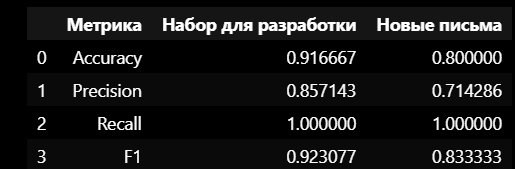

**6.2. Написать вывод (5-7 предл.).**

Ответьте своими словами. Одних чисел недостаточно. Можно опереться на пункты:

1) какие признаки оказались полезными;
2) что произошло с Precision и Recall при изменении порога;
3) какой тип ошибки неприятнее для спам-фильтра – FP или FN – и почему;
4) чем эта работа похожа на экспертную систему и чем отличается;
5) почему этот фильтр нельзя называть полноценной ML-моделью;
6) что мог бы сделать алгоритм ML вместо вас и что все равно готовит человек;
7) какой пример из тестового набора оказался самым неожиданным.

**Главный вывод работы:** простой фильтр можно создать вручную, но его правила ограничены теми признаками и ситуациями, которые заранее предусмотрел человек. Метрики и отдельный тест показывают цену этих ограничений; машинное обучение меняет способ получения правил, но не отменяет признаки, метки и критерий качества.

Полезные признаки: сильнее всех — asks_sensitive (запрос пароля/кода/данных), за ним unknown_sender и накопительный suspicious_term; слабее всех — has_link, он есть почти везде.

Порог: при низком пороге Recall = 1.0, но Precision падает из-за ложных тревог; при высоком — Precision = 1.0, но Recall падает до 0.5. Порог 3 дал баланс: FP = 0 при Recall - 0.67.

FP vs FN: для почты FP (нормальное письмо в спаме) неприятнее — потеря рабочего письма дороже лишней рекламы, поэтому приоритет у Precision.

Экспертная система vs ML: фильтр похож на экспертную систему — правила придумал человек, — но это не ML-модель: веса и порог заданы вручную, ничего не обучено на данных. ML мог бы сам подобрать веса и порог, но человек всё равно готовит признаки, разметку и критерий качества.

Неожиданный пример: T02 — нормальное рабочее письмо от нового партнёра ушло в спам только из-за незнакомого отправителя и ссылки; оно набрало те же 3 балла, что и спам D07/D09, — порогом их не разделить.

**Пояснение к части 6.** Своими словами записать (2-3 предл.): главный вывод работы.

Были выбраны ложные тревоги T02 и T08, их причина — слишком высокий вес unknown_sender. Гипотеза: если понизить его с 2 до 1, нормальные письма от новых партнёров перестанут блокироваться, но может вырасти пропуск спама. 

Проверка на наборе для разработки подтвердила: FP уменьшились до 0 (D12 перестал блокироваться), но FN выросли с 2 до 3 — D07 и D09 опустились ниже порога. Итоговые метрики: Precision осталась 1.0, Recall упал с 0.67 до 0.5, F1 — с 0.80 до 0.67. 

## Справочные ресурсы

| Ресурс | Для чего | Адрес |
|---|---|---|
| Mitchell T. Machine Learning, 1997 | задача, опыт, мера качества | https://www.cs.cmu.edu/~tom/mlbook.html |
| Документация Python: встроенные типы | списки, словари, множества | https://docs.python.org/3/library/stdtypes.html |
| Основы Markdown | оформление текстовых ячеек | https://www.markdownguide.org/basic-syntax/ |

**Что должно быть в сданном ноутбуке.** Заполненные ячейки с данными; список признаков и веса; функции фильтра; выбранный порог с объяснением; ручной подсчет TP, TN, FP, FN; реализация метрик; итоговые числа; разбор хотя бы двух ошибок (если ошибок меньше – объясните, почему это не доказывает универсальную надежность); выводы своими словами.